**Imports**

from example notebook

In [1]:
import gzip, json
import pandas as pd

spec_files = pd.read_parquet('data/spec_files.parquet')
features = pd.read_parquet('data/spec_content_features.parquet')
prs = pd.read_parquet('data/pull_requests.parquet')
pr_files = pd.read_parquet('data/pr_files.parquet')
links = pd.read_parquet('data/spec_links.parquet')
kiro = pd.read_parquet('data/kiro_files.parquet')
print(f'{len(spec_files):,} specs across {spec_files.repo_name.nunique():,} repos')

28,583 specs across 415 repos


**Filter Specs**

keep specs that are English, meet minimum content quantity and quality requirements

In [34]:
features_copy = features.copy()
# Filter non-English
english = features_copy[features_copy["lang"].eq("en")].copy()
print(len(features_copy), "Original specs")
print(len(english), "English specs")
#print(f"{(features_copy["lang"].eq("en").mean() * 100):.4f}", "% Original classified as English")
# Filter empty or nearly empty specs
usable = english[
    (english["n_words"] >= 100) &
    (english["n_lines"] >= 10) &
    (english["n_headings"] >= 2)
].copy()
print(len(usable), "English specs meeting minimum num words, lines, headings")
#print(f"{(len(usable) / len(english) * 100):.4f}", "% English specs deemed usable")
# Filter specs with placeholders or unfinished material
usable = usable[
    (usable["has_lorem"].fillna(0) == 0) &
    (usable["has_unfilled_placeholder"].fillna(0) == 0)
].copy()
print(len(usable), "Usable specs without placeholders")
# Require minimum of spec quality features
requirement_features = [
    "has_requirements",
    "has_acceptance_criteria",
    "has_user_scenarios",
    "has_success_criteria",
    "has_purpose",
    "has_overview",
    "has_edge_cases",
    "has_dependencies"
]

usable["n_substantive_sections"] = (
    usable[requirement_features]
    .fillna(0)
    .sum(axis=1)
)

eligible = usable[
    usable["n_substantive_sections"] >= 2
].copy()

print(len(eligible), "Eligible specs with 2+ quality features")


28583 Original specs
27936 English specs
26161 English specs meeting minimum num words, lines, headings
24240 Usable specs without placeholders
6336 Eligible specs with 2+ quality features


**Spec content quantity distribution**

In [4]:
display(
    english[
        ["n_words", "n_lines", "n_headings"]
    ].describe(
        percentiles=[
            .01, .05, .10, .25,
            .50, .75, .90, .95, .99
        ]
    )
)

,n_words,n_lines,n_headings
count,27936.000000,27936.00000,27936.000000
mean,736.771084,90.04700,14.491982
std,1132.285330,130.31456,15.723593
min,7.000000,2.00000,0.000000
1%,59.000000,9.00000,3.000000
5%,91.000000,13.00000,3.000000
10%,126.000000,18.00000,4.000000
25%,224.000000,30.00000,6.000000
50%,423.000000,56.00000,11.000000
75%,839.000000,107.00000,18.000000


In [35]:
# Load the relevant tables

pull_requests = prs

# PR identity must include all three fields.
PR_KEY = ["tool", "repo_name", "pr_number"]

# --------------------------------------------------
# 2. Prepare eligible spec metadata
# --------------------------------------------------

# eligible is the DataFrame produced by your earlier filtering.
spec_meta = eligible[["file_url_sha16"]].merge(
    spec_files[
        ["file_url_sha16", "repo_name", "file_path", "spec_tool"]
    ],
    on="file_url_sha16",
    how="left"
).rename(columns={"spec_tool": "tool"})

# Remove specs without repository/path metadata.
spec_meta = spec_meta.dropna(
    subset=["tool", "repo_name", "file_path"]
).drop_duplicates("file_url_sha16")

# --------------------------------------------------
# 3. Find initial implementation PRs
# --------------------------------------------------

# PRs that modified an eligible spec file.
spec_changes = pr_files[pr_files["is_spec"].eq(1)].merge(
    spec_meta,
    on=["tool", "repo_name", "file_path"],
    how="inner"
)

# Add PR metadata.
pr_metadata = pull_requests[
    PR_KEY + ["merged_at", "is_merged", "touches_code"]
].drop_duplicates(PR_KEY)

spec_changes = spec_changes.merge(
    pr_metadata,
    on=PR_KEY,
    how="inner"
)

# Keep merged PRs that also changed source code.
initial_candidates = spec_changes[
    (spec_changes["is_merged"].eq(1)) &
    (spec_changes["touches_code"].eq(1))
].copy()

initial_candidates["merged_at"] = pd.to_datetime(
    initial_candidates["merged_at"], errors="coerce", utc=True
)

initial_candidates = initial_candidates.dropna(subset=["merged_at"])

# Select the earliest qualifying PR for each spec.
initial_candidates = initial_candidates.sort_values("merged_at")

initial_prs = (
    initial_candidates
    .drop_duplicates("file_url_sha16")
    [["file_url_sha16"] + PR_KEY + ["merged_at"]]
    .rename(columns={
        "pr_number": "initial_pr",
        "merged_at": "initial_date"
    })
)

print("Specs with an identified initial implementation:",
      f"{len(initial_prs):,}")

# --------------------------------------------------
# 4. Identify code paths changed by each initial PR
# --------------------------------------------------

initial_code = pr_files[pr_files["is_code"].eq(1)].merge(
    initial_prs,
    left_on=PR_KEY,
    right_on=["tool", "repo_name", "initial_pr"],
    how="inner"
)

# A set of code paths for each initial implementation.
initial_paths = (
    initial_code.groupby("file_url_sha16")["file_path"]
    .agg(set)
    .to_dict()
)

# --------------------------------------------------
# 5. Prepare later code-changing PRs
# --------------------------------------------------

# The PR table only contains spec-associated PRs.
# Keep merged PRs that also changed code.
later_pr_metadata = pull_requests[
    pull_requests["is_merged"].eq(1) &
    pull_requests["touches_code"].eq(1)
].copy()

later_pr_metadata["merged_at"] = pd.to_datetime(
    later_pr_metadata["merged_at"], errors="coerce", utc=True
)

later_pr_metadata = later_pr_metadata.dropna(subset=["merged_at"])

later_code = pr_files[pr_files["is_code"].eq(1)].merge(
    later_pr_metadata[PR_KEY + ["merged_at"]],
    on=PR_KEY,
    how="inner"
)

# Store each PR's modified code paths.
later_prs = (
    later_code.groupby(PR_KEY + ["merged_at"])["file_path"]
    .agg(set)
    .reset_index(name="code_paths")
)

# Group later PRs by repository and tool for faster lookup.
later_by_repo = {
    key: group.sort_values("merged_at")
    for key, group in later_prs.groupby(["tool", "repo_name"])
}

# --------------------------------------------------
# 6. Count follow-up PRs within each time window
# --------------------------------------------------

WINDOWS = [30, 90, 180]
results = []

for _, spec in initial_prs.iterrows():

    spec_id = spec["file_url_sha16"]
    tool = spec["tool"]
    repo = spec["repo_name"]
    initial_pr = spec["initial_pr"]
    initial_date = spec["initial_date"]

    original_paths = initial_paths.get(spec_id, set())

    # Without identifiable initial code paths, the
    # follow-up count cannot be calculated.
    if not original_paths:
        results.append({
            "file_url_sha16": spec_id,
            "initial_pr": initial_pr,
            "initial_date": initial_date,
            "followup_fixes_30d": pd.NA,
            "followup_fixes_90d": pd.NA,
            "followup_fixes_180d": pd.NA
        })
        continue

    repo_prs = later_by_repo.get((tool, repo))

    counts = {window: 0 for window in WINDOWS}

    if repo_prs is not None:

        for _, pr in repo_prs.iterrows():

            # Exclude the initial implementation PR.
            if pr["pr_number"] == initial_pr:
                continue

            days_after = (
                pr["merged_at"] - initial_date
            ).total_seconds() / 86400

            # Only count PRs merged after implementation.
            if days_after <= 0:
                continue

            # Count only PRs modifying at least one
            # code path changed by the initial PR.
            if not original_paths.intersection(pr["code_paths"]):
                continue

            for window in WINDOWS:
                if days_after <= window:
                    counts[window] += 1

    results.append({
        "file_url_sha16": spec_id,
        "initial_pr": initial_pr,
        "initial_date": initial_date,
        "followup_fixes_30d": counts[30],
        "followup_fixes_90d": counts[90],
        "followup_fixes_180d": counts[180]
    })

followups = pd.DataFrame(results)

# --------------------------------------------------
# 7. Attach results to all eligible specs
# --------------------------------------------------

spec_results = eligible.merge(
    followups,
    on="file_url_sha16",
    how="left"
)

# Specs without an initial implementation remain NA,
# rather than being incorrectly assigned zero follow-ups.

print("\nFollow-up analysis")
print("------------------")
print("Eligible specs:", len(spec_results))
print("With initial implementation:", spec_results["initial_pr"].notna().sum())
print("With measurable code paths:", spec_results["followup_fixes_90d"].notna().sum())

print("\n90-day follow-up count distribution:")
print(spec_results["followup_fixes_90d"].value_counts(dropna=False).sort_index())

# Save the results.
spec_results.to_parquet("eligible_spec_followups.parquet", index=False)
spec_results.to_csv("eligible_spec_followups.csv", index=False)


Specs with an identified initial implementation: 3,729

Follow-up analysis
------------------
Eligible specs: 6336
With initial implementation: 3729
With measurable code paths: 3729

90-day follow-up count distribution:
followup_fixes_90d
0.0       451
1.0       357
2.0       293
3.0       242
4.0       375
         ... 
82.0       21
89.0       11
98.0        9
101.0       6
NaN      2607
Name: count, Length: 78, dtype: int64


In [25]:
print(
    spec_results[
        [
            "followup_fixes_30d",
            "followup_fixes_90d",
            "followup_fixes_180d"
        ]
    ].describe()
)

       followup_fixes_30d  followup_fixes_90d  followup_fixes_180d
count         1271.000000         1271.000000          1271.000000
mean             4.917388            7.645948             8.970889
std              7.243587           11.398600            14.359444
min              0.000000            0.000000             0.000000
25%              1.000000            1.000000             1.000000
50%              2.000000            4.000000             4.000000
75%              6.000000            9.000000            11.000000
max             45.000000          101.000000           105.000000


**Constructing a quality score**
The code below produces a score from 0-8. A spec receives one point for each feature it contains.

In [36]:
quality_features = [
    "has_requirements",
    "has_acceptance_criteria",
    "has_user_scenarios",
    "has_success_criteria",
    "has_purpose",
    "has_overview",
    "has_edge_cases",
    "has_dependencies"
]

spec_results["quality_score"] = (
    spec_results[quality_features]
    .fillna(0)
    .sum(axis=1)
)

**Associate quality with follow-up PR counts**

   quality_score  count       mean  median
0              2   2458  16.385679     7.0
1              3    405  10.822222     5.0
2              4    628   6.764331     3.0
3              5    215   4.516279     3.0
4              6     21   5.333333     3.0
5              7      2   2.000000     2.0
Spearman correlation: -0.2417
P-value: 0.000000


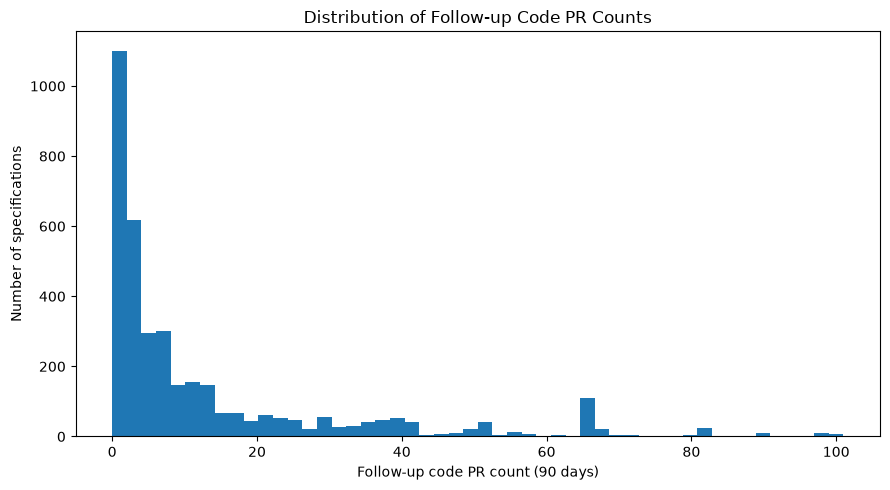

Optimization terminated successfully.
         Current function value: 3.518723
         Iterations: 10
         Function evaluations: 13
         Gradient evaluations: 13
                     NegativeBinomial Regression Results                      
Dep. Variable:     followup_fixes_90d   No. Observations:                 3729
Model:               NegativeBinomial   Df Residuals:                     3727
Method:                           MLE   Df Model:                            1
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                 0.01229
Time:                        11:28:09   Log-Likelihood:                -13121.
converged:                       True   LL-Null:                       -13285.
Covariance Type:            nonrobust   LLR p-value:                 5.324e-73
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         3.6344      0.

In [37]:
analysis = spec_results.dropna(
    subset=["quality_score", "followup_fixes_90d"]
)

quality_summary = (
    analysis
    .groupby("quality_score")
    ["followup_fixes_90d"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

print(quality_summary)

from scipy.stats import spearmanr
rho, p_value = spearmanr(
    analysis["quality_score"],
    analysis["followup_fixes_90d"]
)
print(f"Spearman correlation: {rho:.4f}")
print(f"P-value: {p_value:.6f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.hist(
    analysis["followup_fixes_90d"],
    bins=50
)
plt.xlabel("Follow-up code PR count (90 days)")
plt.ylabel("Number of specifications")
plt.title("Distribution of Follow-up Code PR Counts")
plt.tight_layout()
plt.show()

import statsmodels.formula.api as smf
model = smf.negativebinomial(
    "followup_fixes_90d ~ quality_score",
    data=analysis
).fit()
print(model.summary())